# 04 — CHT forest ecohydrology: 2017–2022 district-month panel

**Standalone local Jupyter notebook · three CHT districts · Earth Engine project from config**

**Study stage:** Extend the quality-audited 2020 Notebook 03 pilot to a six-year satellite/model-derived indicator dataset. This is descriptive Earth observation analysis, not independent ecohydrological validation or a machine-learning experiment.

The 2020 pilot yielded complete rainfall time coverage but **low strict-quality EVI support in June–August (all nine district-month combinations)** and **limited ET main-algorithm support in ten of 36 district-month combinations**. We do not conceal these limitations or treat missing or low-support data as genuine zeros.

**Run one year at a time.** The notebook saves a separate, reusable local result for each *completed* calendar year. When all six years are available, it combines them into one panel without rerunning cached years. It uses only small Earth Engine table requests, not raster downloads. It never writes to GEE, alters the input shapefile, publishes to GitHub, or trains a model.

Read `docs/04_research_limitations_and_future_directions.md` (supplied with this notebook) for the living research limitations and future-research register. We will integrate and refine it when writing the paper and portfolio page.


## 1. Fixed products and scientific boundaries

| Variable | Earth Engine asset | Temporal treatment | Interpretation |
|---|---|---|---|
| District-wide rainfall | [CHIRPS v3 daily reanalysis](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL) | Sum all daily images in month | 0.05° station–satellite rainfall estimate, not forest-only rainfall |
| Forest EVI | [MOD13Q1 v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD13Q1) | Median of 16-day composites **starting** within month | QA 0 only; value needs spatial-support check |
| Forest ET | [MOD16A2GF v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD16A2GF) | Apportion 8-day totals by days overlapping month | Modeled, pre-gap-filled ET, **not field-measured ET** |
| Forest mask | [MCD12Q1 v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD12Q1) | **Fixed 2021** IGBP forest classes 1–5 | Consistent retrospective forest classification; no land-cover change claim |

**Fixed QA diagnostics (same as Notebook 03):**

- `evi_support_flag='low'` if fewer than **25%** of MODIS-classified forest pixels have an accepted EVI composite that month. This is a screening threshold, *not validated accuracy*.
- The raw `evi_forest` remains in the dataset for transparency. `evi_forest_screened` is missing (NaN) for low-support months. No invented optical values or gap-filling.
- ET pixels with fewer than 90% temporal composite-day support are masked, as in Notebook 03. `et_day_support` describes coverage, **not model reliability**.
- **New:** `et_main_support_flag='limited'` when fewer than 50% of monthly days are supported by the MOD16 main algorithm. The 50% threshold is exploratory, not an official validation criterion. Original modeled ET values remain unchanged.

Interpret rainfall, EVI and ET **separately at their documented spatial supports**. Do not subtract rainfall minus forest ET to claim water balance or correlate them as independent field measurements.


## 2. Local configuration — choose the year

Start with `YEARS_TO_RUN = [2017]`. Once that year saves successfully, switch to `YEARS_TO_RUN = ALL_YEARS` and run all cells again. Matching completed year files are reused automatically, while missing years are calculated.

Outputs are stored in `outputs/tables/04_yearly_cache/` and `outputs/tables/` on **your PC**. Existing `03_*` pilot files are never changed. If you alter the methodological settings or original boundary, the notebook refuses to reuse an incompatible cached year: preserve earlier results and agree a new study recipe before starting a replacement run.


In [1]:
from pathlib import Path
from shapely.geometry import mapping
import hashlib
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'configs' / 'study_config.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Launch JupyterLab from the research root or notebooks directory.')
CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
ALL_YEARS = list(range(int(CONFIG['study_start'][:4]),
                       int(CONFIG['study_end_exclusive'][:4])))
assert ALL_YEARS == list(range(2017, 2023)), 'This notebook was designed for 2017–2022.'
YEARS_TO_RUN = ALL_YEARS  # After a successful test, use: ALL_YEARS

EVI_STRICT_QA = 0
MIN_EVI_FOREST_COVERAGE = 0.25
MIN_ET_PIXEL_DAY_COVERAGE = 0.90
MIN_ET_MAIN_SUPPORT = 0.50  # A diagnostic flag, NOT a validated accuracy cutoff
FOREST_MAP_YEAR = 2021

assert YEARS_TO_RUN and len(set(YEARS_TO_RUN)) == len(YEARS_TO_RUN)
assert all(year in ALL_YEARS for year in YEARS_TO_RUN)
BOUNDARY_PATH = ROOT / CONFIG['boundary_relative_path']
DISTRICTS = gpd.read_file(BOUNDARY_PATH)
NAME = CONFIG['district_name_field']
assert DISTRICTS.crs is not None and DISTRICTS.geometry.is_valid.all()
assert len(DISTRICTS) == 3 and set(DISTRICTS[NAME]) == set(CONFIG['expected_districts'])
DISTRICTS = DISTRICTS.to_crs('EPSG:4326')

def fingerprint_shapefile(path):
    digest = hashlib.sha256()
    for suffix in ('.shp', '.shx', '.dbf', '.prj', '.cpg'):
        component = path.with_suffix(suffix)
        if component.exists():
            digest.update(component.name.encode('utf-8'))
            digest.update(component.read_bytes())
    return digest.hexdigest()

RECIPE = {
    'cloud_project_id': CONFIG['gee_project_id'],
    'boundary_file': CONFIG['boundary_relative_path'],
    'boundary_sha256': fingerprint_shapefile(BOUNDARY_PATH),
    'research_years': ALL_YEARS,
    'forest_map_year': FOREST_MAP_YEAR,
    'evi_summary_qa_equal': EVI_STRICT_QA,
    'min_evi_forest_coverage': MIN_EVI_FOREST_COVERAGE,
    'min_et_pixel_day_coverage': MIN_ET_PIXEL_DAY_COVERAGE,
    'min_et_main_algorithm_day_support': MIN_ET_MAIN_SUPPORT,
    'rain_dataset': 'UCSB-CHC/CHIRPS/V3/DAILY_RNL',
    'evi_dataset': 'MODIS/061/MOD13Q1',
    'et_dataset': 'MODIS/061/MOD16A2GF',
    'landcover_dataset': 'MODIS/061/MCD12Q1',
    'evi_month_convention': '16-day composite start date in calendar month',
    'et_month_convention': '8-day amounts weighted by calendar day overlap'
}
CACHE = ROOT / 'outputs' / 'tables' / '04_yearly_cache'
OUT = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
print('Project:', ROOT)
print('GEE project:', CONFIG['gee_project_id'])
print('Available research years:', ALL_YEARS)
print('Years this run:', YEARS_TO_RUN)
print('Original boundaries: three district features (not dissolved)')


Project: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml
GEE project: axial-paratext-491911-b6
Available research years: [2017, 2018, 2019, 2020, 2021, 2022]
Years this run: [2017, 2018, 2019, 2020, 2021, 2022]
Original boundaries: three district features (not dissolved)


## 3. Earth Engine datasets and fixed forest population

The study retains the **2021 forest reference mask in every study year**. This allows like-for-like comparison for a retrospectively defined forest population, but it does not establish forest cover in each historical year. The local shapefile is untouched; only a temporary simplified geometry is passed to GEE.


In [2]:
ee.Initialize(project=CONFIG['gee_project_id'])
GEE_DISTRICTS = ee.FeatureCollection([
    ee.Feature(ee.Geometry(mapping(row.geometry.simplify(0.001, preserve_topology=True))),
               {'district': str(row[NAME])})
    for _, row in DISTRICTS.iterrows()
])
RAIN = ee.ImageCollection(RECIPE['rain_dataset'])
VEG = ee.ImageCollection(RECIPE['evi_dataset'])
ET = ee.ImageCollection(RECIPE['et_dataset'])
LC = ee.ImageCollection(RECIPE['landcover_dataset'])
lc_year = LC.filterDate('2021-01-01', '2022-01-01')
assert lc_year.size().getInfo() == 1, 'Expected exactly one MODIS 2021 land-cover map.'
IGBP = ee.Image(lc_year.first()).select('LC_Type1')
FOREST = IGBP.gte(1).And(IGBP.lte(5)).rename('forest_modis_2021')

def table_from_regions(image, scale_m, band_names):
    img = ee.Image(image)
    # Explicitly name reducer outputs: the plain mean reducer sometimes returns
    # the literal column name 'mean' instead of the input image band name.
    features = img.reduceRegions(
        collection=GEE_DISTRICTS,
        reducer=ee.Reducer.mean().forEachBand(img),
        scale=scale_m, tileScale=4)
    no_geometry = features.map(lambda f: ee.Feature(None, ee.Feature(f).toDictionary()))
    records = [feature['properties'] for feature in no_geometry.getInfo()['features']]
    if len(records) != len(CONFIG['expected_districts']):
        raise RuntimeError(f'Expected 3 reduced districts; got {len(records)}.')
    df = pd.DataFrame(records).reindex(columns=['district', *band_names])
    if set(df['district']) != set(CONFIG['expected_districts']):
        raise RuntimeError('GEE district identifiers did not match the study configuration.')
    return df

forest_summary = table_from_regions(
    FOREST.toFloat().rename('forest_fraction_2021'), 500,
    ['forest_fraction_2021'])
if forest_summary['forest_fraction_2021'].isna().any():
    raise RuntimeError('MCD12Q1 lacks valid pixels for a district; stop.')
display(forest_summary.round(4))


,district,forest_fraction_2021
0,Bandarban,0.3371
1,Khagrachhari,0.2314
2,Rangamati,0.4156


## 4. Reuse Notebook 03's exact EVI and ET transformations

This step deliberately preserves the 2020 pilot's QA mask, unit conversions, temporal weighting and district aggregation. No ML features, imputation, alternative sensors or hidden quality adjustments are introduced during the multi-year extension.


In [3]:
def quality_evi(image):
    img = ee.Image(image)
    raw = img.select('EVI')
    good = img.select('SummaryQA').eq(EVI_STRICT_QA)
    plausible = raw.gte(-2000).And(raw.lte(10000))
    return raw.multiply(0.0001).updateMask(good.And(plausible)).rename('evi')


def weighted_et_composite(image, month_start, month_end):
    image = ee.Image(image)
    start = image.date()
    year_end = ee.Date.fromYMD(ee.Number(start.get('year')).add(1), 1, 1)
    period_end = ee.Date(ee.Number(start.advance(8, 'day').millis())
                         .min(year_end.millis()))
    overlap_start = ee.Date(ee.Number(start.millis()).max(month_start.millis()))
    overlap_end = ee.Date(ee.Number(period_end.millis()).min(month_end.millis()))
    days = ee.Number(overlap_end.difference(overlap_start, 'day')).max(0)
    period_length = ee.Number(period_end.difference(start, 'day'))
    raw_et = image.select('ET')
    valid = raw_et.gte(0).And(raw_et.lt(32700))
    main_algorithm = image.select('ET_QC').bitwiseAnd(1).eq(0)
    mm = raw_et.multiply(0.1).multiply(days.divide(period_length)).updateMask(valid)
    valid_days = raw_et.multiply(0).add(days).updateMask(valid)
    main_days = raw_et.multiply(0).add(days).updateMask(valid.And(main_algorithm))
    return ee.Image.cat([mm.rename('et_weighted_mm'),
                         valid_days.rename('et_valid_days'),
                         main_days.rename('et_main_algorithm_days')]).toFloat()


FOREST_BANDS = ['evi_forest', 'evi_qa_pixel_support', 'et_mm_forest',
                'et_day_support', 'et_main_algorithm_day_support']

def extract_month(year, month_number):
    first = pd.Timestamp(year=year, month=month_number, day=1)
    following = first + pd.offsets.MonthBegin(1)
    start, end = first.strftime('%Y-%m-%d'), following.strftime('%Y-%m-%d')
    start_ee, end_ee = ee.Date(start), ee.Date(end)
    month_days = int((following - first).days)
    label = first.strftime('%Y-%m')

    rain_collection = RAIN.filterDate(start, end).select('precipitation')
    rain_count = rain_collection.size().getInfo()
    if rain_count != month_days:
        raise RuntimeError(f'{label} CHIRPS has {rain_count}/{month_days} daily images. STOP.')
    rain_mm = rain_collection.sum().rename('rain_mm_district')
    rain_stats = table_from_regions(rain_mm, 5566, ['rain_mm_district'])
    if rain_stats['rain_mm_district'].isna().any():
        raise RuntimeError(f'{label} CHIRPS district mean is missing. STOP.')

    veg_collection = VEG.filterDate(start, end)
    n_veg = veg_collection.size().getInfo()
    if n_veg == 0:
        raise RuntimeError(f'{label} MOD13Q1 has no 16-day composites. STOP.')
    evi = veg_collection.map(quality_evi).median().rename('evi_forest')
    evi_support = evi.mask().unmask(0).rename('evi_qa_pixel_support')

    et_collection = ET.filterDate(start_ee.advance(-8, 'day'), end_ee)
    n_et = et_collection.size().getInfo()
    if n_et == 0:
        raise RuntimeError(f'{label} MOD16A2GF has no nearby 8-day composites. STOP.')
    weighted = et_collection.map(
        lambda image: weighted_et_composite(image, start_ee, end_ee))
    et_sum = weighted.select('et_weighted_mm').sum()
    valid_fraction = weighted.select('et_valid_days').sum().divide(month_days)
    main_fraction = weighted.select('et_main_algorithm_days').sum().divide(month_days)
    valid_fraction = valid_fraction.unmask(0).clamp(0, 1)
    main_fraction = main_fraction.unmask(0).clamp(0, 1)
    et_month = et_sum.updateMask(valid_fraction.gte(MIN_ET_PIXEL_DAY_COVERAGE))

    forest_stack = ee.Image.cat([
        evi.updateMask(FOREST).rename('evi_forest'),
        evi_support.updateMask(FOREST).rename('evi_qa_pixel_support'),
        et_month.updateMask(FOREST).rename('et_mm_forest'),
        valid_fraction.updateMask(FOREST).rename('et_day_support'),
        main_fraction.updateMask(FOREST).rename('et_main_algorithm_day_support')
    ])
    forest_stats = table_from_regions(forest_stack, 500, FOREST_BANDS)
    row = rain_stats.merge(forest_stats, on='district', validate='one_to_one')
    row = row.merge(forest_summary, on='district', validate='one_to_one')
    row.insert(0, 'month', label)
    row.insert(0, 'year', year)
    row['month_days'] = month_days
    row['rain_days'] = rain_count
    row['evi_composites_by_start'] = n_veg
    row['et_composites_near_month'] = n_et
    row['evi_support_flag'] = row['evi_qa_pixel_support'].apply(
        lambda v: 'low' if pd.isna(v) or v < MIN_EVI_FOREST_COVERAGE else 'ok')
    row['et_coverage_flag'] = row['et_day_support'].apply(
        lambda v: 'low' if pd.isna(v) or v < MIN_ET_PIXEL_DAY_COVERAGE else 'ok')
    row['et_main_support_flag'] = row['et_main_algorithm_day_support'].apply(
        lambda v: 'limited' if pd.isna(v) or v < MIN_ET_MAIN_SUPPORT else 'higher')
    row['evi_forest_screened'] = row['evi_forest'].where(
        row['evi_support_flag'].eq('ok'))
    month_inventory = {
        'year': year, 'month': label, 'calendar_days': month_days,
        'chirps_daily_images': rain_count,
        'evi_16day_composites': n_veg,
        'et_8day_composites_considered': n_et
    }
    return row, month_inventory


## 5. Extract one year, save it, and safely resume later

This can take several minutes, depending on GEE response time. Each completed month prints its date; **annual files are saved only after all 12 months pass validation**. If Jupyter is interrupted halfway through a year, rerun that year. A successfully saved year is reused only if its accompanying method manifest matches your current settings and shapefile fingerprint.

The cache is intentionally append-by-year: nothing deletes, overwrites or silently replaces an existing completed year's results.


In [4]:
def paths_for_year(year):
    return (CACHE / f'04_{year}_monthly.csv',
            CACHE / f'04_{year}_inventory.csv',
            CACHE / f'04_{year}_method.json')


def validate_year(frame, year):
    needed = {'district', 'month', 'year', 'rain_mm_district',
              'evi_forest', 'evi_qa_pixel_support', 'et_mm_forest',
              'et_day_support', 'et_main_algorithm_day_support',
              'evi_support_flag', 'et_main_support_flag', 'evi_forest_screened'}
    if not needed.issubset(frame.columns):
        raise RuntimeError(f'{year}: missing output columns: {needed - set(frame.columns)}')
    if len(frame) != 36 or frame[['district', 'month']].duplicated().any():
        raise RuntimeError(f'{year}: expected 36 unique district-month records.')
    if set(frame['district']) != set(CONFIG['expected_districts']):
        raise RuntimeError(f'{year}: district names do not match the study boundary.')
    if set(frame['month']) != {f'{year}-{m:02d}' for m in range(1, 13)}:
        raise RuntimeError(f'{year}: missing or unexpected calendar month.')
    if not frame['year'].eq(year).all():
        raise RuntimeError(f'{year}: wrong year in cached records.')
    if frame['rain_mm_district'].isna().any() or not frame['rain_days'].eq(frame['month_days']).all():
        raise RuntimeError(f'{year}: rainfall values or daily coverage incomplete.')
    if not frame['rain_mm_district'].ge(0).all():
        raise RuntimeError(f'{year}: invalid negative rainfall.')
    for field in ['forest_fraction_2021', 'evi_qa_pixel_support',
                  'et_day_support', 'et_main_algorithm_day_support']:
        if not frame[field].dropna().between(0, 1).all():
            raise RuntimeError(f'{year}: {field} is outside [0,1].')
    if (frame['et_main_algorithm_day_support'] > frame['et_day_support'] + 1e-6).any():
        raise RuntimeError(f'{year}: ET main-algorithm days exceed valid days.')


CACHE.mkdir(parents=True, exist_ok=True)
for year in YEARS_TO_RUN:
    monthly_path, inventory_path, method_path = paths_for_year(year)
    existing = [p.exists() for p in (monthly_path, inventory_path, method_path)]
    if any(existing):
        if not all(existing):
            raise RuntimeError(f'{year}: partial year cache found; stop and inspect files.')
        method = json.loads(method_path.read_text(encoding='utf-8'))
        if method != RECIPE:
            raise RuntimeError(f'{year}: cache was produced with a different method or boundary. '
                               'Keep the existing research files and request a new version.')
        cached = pd.read_csv(monthly_path)
        validate_year(cached, year)
        print(f'{year}: verified matching cache, no GEE reprocessing.')
        continue

    print(f'{year}: starting 12 calendar months...')
    year_parts, source_rows = [], []
    for month_number in range(1, 13):
        result, source = extract_month(year, month_number)
        year_parts.append(result)
        source_rows.append(source)
        print('  completed', source['month'])
    year_data = pd.concat(year_parts, ignore_index=True).sort_values(
        ['month', 'district']).reset_index(drop=True)
    validate_year(year_data, year)
    year_data.to_csv(monthly_path, index=False)
    pd.DataFrame(source_rows).to_csv(inventory_path, index=False)
    method_path.write_text(json.dumps(RECIPE, indent=2), encoding='utf-8')
    print(f'{year}: saved 36 rows with their source inventory and method record.')


2017: verified matching cache, no GEE reprocessing.
2018: starting 12 calendar months...
  completed 2018-01
  completed 2018-02
  completed 2018-03
  completed 2018-04
  completed 2018-05
  completed 2018-06
  completed 2018-07
  completed 2018-08
  completed 2018-09
  completed 2018-10
  completed 2018-11
  completed 2018-12
2018: saved 36 rows with their source inventory and method record.
2019: starting 12 calendar months...
  completed 2019-01
  completed 2019-02
  completed 2019-03
  completed 2019-04
  completed 2019-05
  completed 2019-06
  completed 2019-07
  completed 2019-08
  completed 2019-09
  completed 2019-10
  completed 2019-11
  completed 2019-12
2019: saved 36 rows with their source inventory and method record.
2020: starting 12 calendar months...
  completed 2020-01
  completed 2020-02
  completed 2020-03
  completed 2020-04
  completed 2020-05
  completed 2020-06
  completed 2020-07
  completed 2020-08
  completed 2020-09
  completed 2020-10
  completed 2020-11
  c

## 6. Combine all completed years and keep quality flags visible

This operation reads already saved local year files. It refuses mismatched cached methods and never pretends that unprocessed years are complete. The yearly results are *not yet* an analysis of trends, causes or hydrological water balance.


In [5]:
available = []
year_frames, source_frames = [], []
for year in ALL_YEARS:
    monthly_path, inventory_path, method_path = paths_for_year(year)
    if not any(p.exists() for p in (monthly_path, inventory_path, method_path)):
        continue
    if not all(p.exists() for p in (monthly_path, inventory_path, method_path)):
        raise RuntimeError(f'{year}: incomplete cached file trio.')
    if json.loads(method_path.read_text(encoding='utf-8')) != RECIPE:
        raise RuntimeError(f'{year}: cached methodology differs from current configuration.')
    frame = pd.read_csv(monthly_path)
    validate_year(frame, year)
    inventory = pd.read_csv(inventory_path)
    if len(inventory) != 12 or not inventory.chirps_daily_images.eq(inventory.calendar_days).all():
        raise RuntimeError(f'{year}: source inventory is incomplete.')
    available.append(year)
    year_frames.append(frame)
    source_frames.append(inventory)

if not available:
    raise RuntimeError('No validated yearly cache is available yet.')

panel = pd.concat(year_frames, ignore_index=True).sort_values(
    ['year', 'month', 'district']).reset_index(drop=True)
all_inventory = pd.concat(source_frames, ignore_index=True)
assert len(panel) == 36 * len(available)
assert not panel[['district', 'month']].duplicated().any()

annual = panel.groupby(['district', 'year'], as_index=False).agg(
    annual_district_rain_mm=('rain_mm_district', lambda s: s.sum(min_count=12)),
    annual_modeled_forest_et_mm=('et_mm_forest', lambda s: s.sum(min_count=12)),
    low_evi_support_months=('evi_support_flag', lambda s: int((s == 'low').sum())),
    limited_et_main_months=('et_main_support_flag', lambda s: int((s == 'limited').sum())),
    average_et_main_day_support=('et_main_algorithm_day_support', 'mean'),
    average_evi_qa_pixel_support=('evi_qa_pixel_support', 'mean'),
    forest_fraction_2021=('forest_fraction_2021', 'first'))

OUT.mkdir(parents=True, exist_ok=True)
panel.to_csv(OUT / '04_available_years_monthly_panel.csv', index=False)
all_inventory.to_csv(OUT / '04_available_years_source_inventory.csv', index=False)
annual.to_csv(OUT / '04_available_years_district_annual_review.csv', index=False)
print('Validated years:', available)
print(f'Panel: {len(panel)} district-month rows; expected 216 only when all 6 years complete.')
print('Low-EVI-support rows:', int((panel.evi_support_flag == 'low').sum()))
print('Limited ET main-algorithm rows:', int((panel.et_main_support_flag == 'limited').sum()))
display(annual.round(3))
if available != ALL_YEARS:
    print('PARTIAL PANEL. Complete remaining years before interpreting six-year patterns.')
else:
    print('FULL SIX-YEAR PANEL assembled. Review quality before further analysis.')


Validated years: [2017, 2018, 2019, 2020, 2021, 2022]
Panel: 216 district-month rows; expected 216 only when all 6 years complete.
Low-EVI-support rows: 63
Limited ET main-algorithm rows: 51


,district,year,annual_district_rain_mm,annual_modeled_forest_et_mm,low_evi_support_months,limited_et_main_months,average_et_main_day_support,average_evi_qa_pixel_support,forest_fraction_2021
0,Bandarban,2017,4189.048,1449.102,4,3,0.748,0.551,0.337
1,Bandarban,2018,3549.804,1459.845,5,3,0.756,0.579,0.337
2,Bandarban,2019,3424.017,1448.379,5,3,0.786,0.517,0.337
3,Bandarban,2020,3442.361,1380.721,3,3,0.750,0.681,0.337
4,Bandarban,2021,3369.110,1355.479,2,3,0.758,0.532,0.337
5,Bandarban,2022,2478.483,1416.952,4,3,0.756,0.640,0.337
6,Khagrachhari,2017,3888.995,1412.404,4,3,0.785,0.569,0.231
7,Khagrachhari,2018,2383.372,1395.114,4,3,0.762,0.474,0.231
8,Khagrachhari,2019,3070.837,1387.248,5,2,0.772,0.455,0.231
9,Khagrachhari,2020,2927.666,1379.923,3,4,0.709,0.659,0.231


FULL SIX-YEAR PANEL assembled. Review quality before further analysis.


## 7. Compare 2020 with the original successful pilot (when both exist)

When 2020 has been reprocessed, this checkpoint compares its unchanged raw fields to `outputs/tables/03_forest_ecohydrology_monthly_pilot.csv`. A mismatch larger than 0.001 is **not** silently accepted: pause to investigate dataset processing or method changes. The new quality flags are additional columns and are not included in the old pilot.


In [6]:
old_pilot = OUT / '03_forest_ecohydrology_monthly_pilot.csv'
if 2020 not in available:
    print('2020 not processed yet; comparison will be possible later.')
elif not old_pilot.exists():
    print('2020 completed, but local Notebook 03 CSV is unavailable. Preserve it for audit.')
else:
    old = pd.read_csv(old_pilot)
    new = panel.loc[panel.year == 2020]
    fields = ['rain_mm_district', 'evi_forest', 'et_mm_forest',
              'evi_qa_pixel_support', 'et_day_support',
              'et_main_algorithm_day_support', 'forest_fraction_2021']
    comparison = new[['district', 'month', *fields]].merge(
        old[['district', 'month', *fields]], on=['district', 'month'],
        suffixes=('_new', '_pilot'), validate='one_to_one')
    if len(comparison) != 36:
        raise RuntimeError(f'Pilot reconciliation has {len(comparison)} rows, expected 36.')
    report = []
    for field in fields:
        new_values = comparison[f'{field}_new']
        pilot_values = comparison[f'{field}_pilot']
        missing_mismatch = new_values.isna().ne(pilot_values.isna()).any()
        max_delta = (new_values - pilot_values).abs().max()
        report.append({'variable': field, 'max_absolute_difference': max_delta,
                       'missing_pattern_mismatch': bool(missing_mismatch)})
    comparison_report = pd.DataFrame(report)
    display(comparison_report)
    if comparison_report['missing_pattern_mismatch'].any() or \
            comparison_report.max_absolute_difference.fillna(0).gt(0.001).any():
        raise RuntimeError('2020 changed from Notebook 03. STOP and review methodology.')
    print('2020 raw values reproduce the original Notebook 03 pilot within 0.001.')


,variable,max_absolute_difference,missing_pattern_mismatch
0,rain_mm_district,0.000000e+00,False
1,evi_forest,1.110223e-16,False
2,et_mm_forest,4.263256e-14,False
3,evi_qa_pixel_support,2.220446e-16,False
4,et_day_support,2.220446e-16,False
5,et_main_algorithm_day_support,1.110223e-16,False
6,forest_fraction_2021,0.000000e+00,False


2020 raw values reproduce the original Notebook 03 pilot within 0.001.


## 8. Inspect the annual rainfall overview

The plot below shows a *district-average rainfall indicator* by complete calendar year. A six-year comparison is not a climate-change trend test. EVI and modeled ET require separate, flag-aware interpretation, so they are not combined into this rainfall figure.


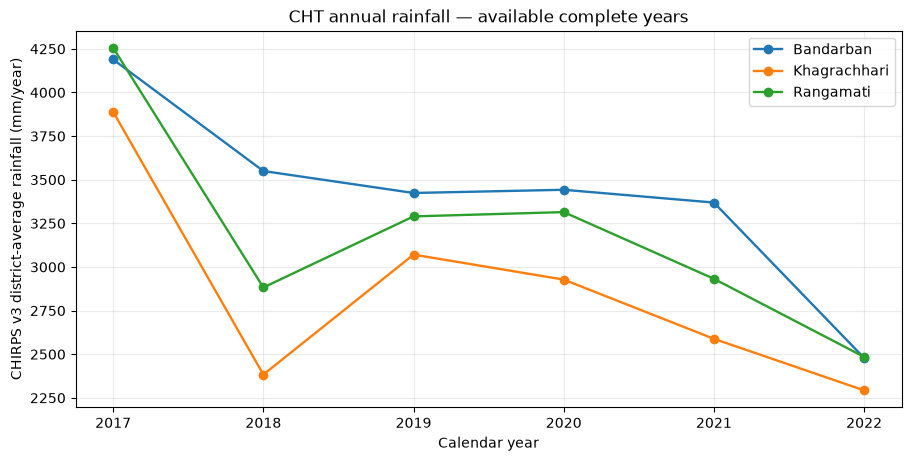

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for district, frame in annual.groupby('district'):
    frame = frame.sort_values('year')
    ax.plot(frame['year'], frame['annual_district_rain_mm'],
            marker='o', linewidth=1.7, label=district)
ax.set(xlabel='Calendar year', ylabel='CHIRPS v3 district-average rainfall (mm/year)',
       title='CHT annual rainfall — available complete years')
ax.set_xticks(available)
ax.grid(alpha=0.25)
ax.legend()
FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / '04_available_years_annual_rainfall.png', dpi=180, bbox_inches='tight')
plt.show()


## 9. Stop for review before interpretation or machine learning

After completing **2017 only**, verify that the notebook produced its yearly cache (36 records), displayed the annual summary and plotted 2017 rainfall. Then change **Section 2** to `YEARS_TO_RUN = ALL_YEARS` and run all cells again. It should **reuse 2017** and calculate 2018–2022 in order.

**When all years finish**, share these four local files with me:

1. `outputs/tables/04_available_years_monthly_panel.csv`
2. `outputs/tables/04_available_years_source_inventory.csv`
3. `outputs/tables/04_available_years_district_annual_review.csv`
4. `outputs/figures/04_available_years_annual_rainfall.png`

We will verify the calendar completeness, monsoon EVI flags and ET main-algorithm support by year. **Do not** publish EVI wet-season peaks, rainfall–ET water balances, causal explanations or ML scores from this extraction notebook.

### Later research limitations and future directions

The supplied research register records limitations already demonstrated by the SMAP feasibility study and 2020 pilot, as well as unresolved methodological constraints in this six-year satellite-only design. Future researchers could add properly designed field soil-moisture/ET measurements, discharge and interception observations, cross-sensor QA tests and spatial-temporal model validation. These are **future research directions**, not tasks or claims completed here.
